# Tutorial 04a

This tutorial uses hourly observations from the Seoul Bike Sharing Demand dataset to predict the number of bikes rented in each hour.

The neural networks are implemented in PyTorch. We compare different architectures by changing the width of the hidden layer and whether a second hidden layer is included. ReLU, Adam, a learning rate of 0.01, and 80 epochs remain fixed so that architecture is the only factor being compared.

The observations remain in chronological order. Earlier dates form the training set, the middle dates form the validation set used to compare architectures, and the latest dates form the test set, which is evaluated once after model selection. All observations from a given date remain in the same subset.

Run the cells from top to bottom.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `seoul_bike.csv`.
- **On your own computer.** Open this file from the `04 Artificial neural networks` folder, so `seoul_bike.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "04 Artificial neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/04 Artificial neural networks


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, scikit-learn scales the columns and scores the predictions, and PyTorch builds the network.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch torchinfo


Note: you may need to restart the kernel to use updated packages.


## Each row is one hour

`seoul_bike.csv` is the Seoul Bike Sharing Demand data, UCI Machine Learning Repository, https://doi.org/10.24432/C5F62R, shared under CC BY 4.0.

`rented` is the count for that hour. The inputs are the hour, the temperature, the humidity, the wind, the visibility, the solar radiation, the rainfall, the snowfall, the season, whether the day is a holiday, and whether the system was open. Temperature and humidity stay in, and the dew point is left out. `date` stays in the table for the time plot at the end. The network's inputs are the columns listed above.

The target is standardised using the training-set mean and standard deviation. Predictions are converted back to bikes per hour before evaluation. Mean absolute error (MAE) therefore represents the average absolute difference, in bikes per hour, between the prediction and observed count.


## What the hours look like

The next cell prints the first rows and a short summary of the count and the weather. The left figure shows how many hours fall at each count. The right figure is the average count at each hour of the day.


rows 8760
columns ['date', 'rented', 'hour', 'temperature_c', 'humidity_pct', 'wind_ms', 'visibility_10m', 'dew_c', 'solar_mj', 'rainfall_mm', 'snowfall_cm', 'season', 'holiday', 'functioning']
         date  rented  hour  temperature_c  humidity_pct  wind_ms  visibility_10m  dew_c  solar_mj  rainfall_mm  snowfall_cm  season     holiday functioning
0  01/12/2017     254     0           -5.2            37      2.2            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
1  01/12/2017     204     1           -5.5            38      0.8            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
2  01/12/2017     173     2           -6.0            39      1.0            2000  -17.7       0.0          0.0          0.0  Winter  No Holiday         Yes
3  01/12/2017     107     3           -6.2            40      0.9            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
4  01/12/2017      78

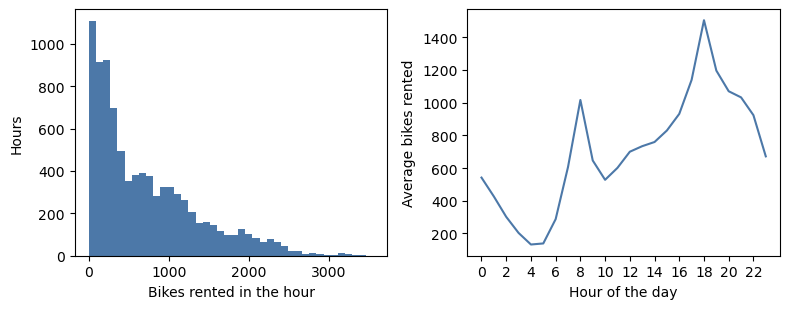

In [4]:
bike = pd.read_csv("seoul_bike.csv")
print("rows", len(bike))
print("columns", list(bike.columns))
print(bike.head().to_string())
print(bike[["rented", "temperature_c", "humidity_pct", "rainfall_mm"]].describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(bike["rented"], bins=40, color="#4C78A8")
axes[0].set_xlabel("Bikes rented in the hour")
axes[0].set_ylabel("Hours")
by_hour = bike.groupby("hour")["rented"].mean()
axes[1].plot(by_hour.index, by_hour.values, color="#4C78A8")
axes[1].set_xlabel("Hour of the day")
axes[1].set_ylabel("Average bikes rented")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()


On the right-hand figure the night sits low, near 100 bikes around 4:00. The average climbs to about 1000 at 8:00, dips through midday, and peaks near 1500 around 18:00. Hour of day is one of the inputs, and this curve is the pattern those inputs have to carry.


## Training days, validation days, test days

The hours are sorted by date, then by hour. There are 365 dates. The first 182 dates, 1 December 2017 through 31 May 2018, are the training set. The next 91 dates, 1 June 2018 through 30 August 2018, are the validation set. The last 92 dates, 31 August 2018 through 30 November 2018, are the test set.

Every hour of a date stays in the same set. The morning and the evening of 1 June are both validation hours, and neither is used to update the weights.

The training dates are winter and spring. The validation dates are summer. Summer has no column of its own in the training table, so a June hour has 0 in both season columns. The temperature and the other weather columns are what mark that hour as warm. The test dates run from the last day of summer into autumn, and autumn is handled the same way.

`StandardScaler` is fit on the training hours only, then applied to the validation hours and the test hours. `y_mean` and `y_std` are the mean and the standard deviation of the training counts. `test_hours` keeps the date, the hour, and the rented count of each test row, in the same order as `X_test`.

`shuffle=True` in the training loader only mixes training hours into batches. Validation dates and test dates stay in the sets named above.


In [5]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

bike = pd.read_csv("seoul_bike.csv")
bike["day"] = pd.to_datetime(bike["date"], dayfirst=True)
bike = bike.sort_values(["day", "hour"]).reset_index(drop=True)
days = bike["day"].drop_duplicates().tolist()
n_days = len(days)
train_days = days[: int(n_days * 0.50)]
valid_days = days[int(n_days * 0.50) : int(n_days * 0.75)]
test_days = days[int(n_days * 0.75) :]
train = bike[bike["day"].isin(train_days)].copy()
valid = bike[bike["day"].isin(valid_days)].copy()
test = bike[bike["day"].isin(test_days)].copy()
print("training days", train_days[0].date(), "to", train_days[-1].date(), len(train_days))
print("validation days", valid_days[0].date(), "to", valid_days[-1].date(), len(valid_days))
print("test days", test_days[0].date(), "to", test_days[-1].date(), len(test_days))

num = ["hour", "temperature_c", "humidity_pct", "wind_ms", "visibility_10m", "solar_mj", "rainfall_mm", "snowfall_cm"]
cat = ["season", "holiday", "functioning"]
X_train_np = pd.concat([train[num].astype(float), pd.get_dummies(train[cat], dtype=int)], axis=1)
X_valid_np = pd.concat([valid[num].astype(float), pd.get_dummies(valid[cat], dtype=int)], axis=1)
X_test_np = pd.concat([test[num].astype(float), pd.get_dummies(test[cat], dtype=int)], axis=1)
X_valid_np = X_valid_np.reindex(columns=X_train_np.columns, fill_value=0)
X_test_np = X_test_np.reindex(columns=X_train_np.columns, fill_value=0)

scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_np).astype("float32")
X_valid_np = scaler.transform(X_valid_np).astype("float32")
X_test_np = scaler.transform(X_test_np).astype("float32")
y_train_np = train["rented"].to_numpy().astype("float32")
y_valid_np = valid["rented"].to_numpy().astype("float32")
y_test_np = test["rented"].to_numpy().astype("float32")
y_mean = float(y_train_np.mean())
y_std = float(y_train_np.std())
test_hours = test[["date", "hour", "rented"]].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
X_valid = torch.tensor(X_valid_np, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test_np, dtype=torch.float32).to(device)
y_train = torch.tensor((y_train_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)
y_valid = torch.tensor((y_valid_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)
y_test = torch.tensor((y_test_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)

print("rows", len(train), len(valid), len(test))
print("input columns", X_train_np.shape[1])
print("training mean", round(y_mean, 1), "training std", round(y_std, 1))


training days 2017-12-01 to 2018-05-31 182
validation days 2018-06-01 to 2018-08-30 91
test days 2018-08-31 to 2018-11-30 92
rows 4368 2184 2208
input columns 14
training mean 480.6 training std 519.6


## A network is a class

`__init__` defines the layers, while `forward` specifies how the hour and weather features pass through them. Each `nn.Linear` layer applies a weighted sum and bias. The `summary` output shows the resulting shape and number of trainable parameters in each layer.

This first network has one hidden layer of 8 units and a single output, the scaled count. The loss is `nn.MSELoss`, the average squared gap between that output and the scaled count. The activation is ReLU: a positive sum is passed on, and a negative sum becomes 0. After this class, one cell trains the 8-unit network. Read that cell from the first line to the last. The loop that compares shapes comes after it, and it uses these same lines.


In [6]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchinfo import summary

class Simple_Network(nn.Module):
    def __init__(self, inp_dim, hid_dim, out_dim):
        super().__init__()
        self.input_layer = nn.Linear(inp_dim, hid_dim)
        self.activation_function = nn.ReLU()
        self.output_layer = nn.Linear(hid_dim, out_dim)

    def forward(self, x):
        h = self.input_layer(x)
        h = self.activation_function(h)
        return self.output_layer(h)

class Two_Layer(nn.Module):
    def __init__(self, inp_dim, hid1, hid2, out_dim):
        super().__init__()
        self.fc1 = nn.Linear(inp_dim, hid1)
        self.fc2 = nn.Linear(hid1, hid2)
        self.fc3 = nn.Linear(hid2, out_dim)
        self.activation_function = nn.ReLU()

    def forward(self, x):
        h = self.activation_function(self.fc1(x))
        h = self.activation_function(self.fc2(h))
        return self.fc3(h)

model = Simple_Network(X_train.shape[1], 8, 1).to(device)
print(summary(model, input_size=(1, X_train.shape[1]), verbose=0))


Layer (type:depth-idx)                   Output Shape              Param #
Simple_Network                           [1, 1]                    --
├─Linear: 1-1                            [1, 8]                    120
├─ReLU: 1-2                              [1, 8]                    --
├─Linear: 1-3                            [1, 1]                    9
Total params: 129
Trainable params: 129
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00


## Train one network

This cell fits the network with one hidden layer of 8 units. The lines follow the order of a fit.

Set the random seed, then build batches of 256 training hours. Create the network, the mean squared error, and Adam with learning rate 0.01. For each of 80 epochs, and for each batch: compute the loss, clear the old gradients, compute the new gradients, and update the weights. After that, turn the validation prediction back into bikes per hour and print the mean absolute error. Eighty epochs and a learning rate of 0.01 give the summer hours a chance to move the weights. A run of 40 epochs at 0.001 stays too close to the winter and spring counts.


In [7]:
from sklearn.metrics import mean_absolute_error

torch.manual_seed(0)
generator = torch.Generator()
generator.manual_seed(0)

loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=True,
    generator=generator,
)

model = Simple_Network(X_train.shape[1], 8, 1).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(80):
    model.train()
    for Xb, yb in loader:
        loss = loss_fn(model(Xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

model.eval()
with torch.no_grad():
    pred = model(X_valid).cpu().numpy().reshape(-1) * y_std + y_mean
print("validation MAE", f"{mean_absolute_error(y_valid_np, pred):.1f}")


validation MAE 435.5


## The sizes have to agree

The output dimension of one layer must match the input dimension of the next. In the example below, `fc1` produces 16 values but `fc2` expects 15, so the forward pass fails. The valid two-layer network used later defines `fc2` with 16 inputs to match the output of `fc1`.


In [8]:
class Unaligned(nn.Module):
    def __init__(self, inp_dim):
        super().__init__()
        self.fc1 = nn.Linear(inp_dim, 16)
        self.fc2 = nn.Linear(15, 8)  # 15 does not match the 16 outputs of fc1
        self.fc3 = nn.Linear(8, 1)
        self.activation_function = nn.ReLU()

    def forward(self, x):
        x = self.activation_function(self.fc1(x))
        x = self.activation_function(self.fc2(x))
        return self.fc3(x)

try:
    Unaligned(X_train.shape[1])(torch.randn(1, X_train.shape[1]))
except RuntimeError as error:
    print(error)


mat1 and mat2 shapes cannot be multiplied (1x16 and 15x8)


## Compare three shapes

The next cell repeats the training above once for each shape. The lines inside the loop are the same lines: 80 epochs, Adam, learning rate 0.01, batches of 256. Only the line that builds the network changes. The random seed is reset before each fit. `shuffle=True` only changes the order of the training hours inside each epoch.

`8` means one hidden layer of 8 units. `32` means one hidden layer of 32 units. `16-8` means two hidden layers, first 16 units and then 8.

Each shape is scored on the validation hours with four numbers. MAE is the average number of bikes the prediction is off by. RMSE is the square root of the average squared error, so a few large misses raise it more than they raise MAE. R2 is 1 when the predictions match the rented counts, and 0 when they are no closer than predicting the average count on every validation hour. MAPE is the average of |predicted − rented| / rented, in percent. Hours that rented fewer than 5 bikes are left out of MAPE: a miss of a few bikes on a count of 1 is a huge percent, and that one hour would dominate the average. Leaving small counts out of MAPE is a common choice. MAE, RMSE, and R2 still use every validation hour. A smaller MAE, RMSE, and MAPE is a closer fit. A larger R2 is a closer fit.


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = np.full(len(y_valid_np), y_mean)
print("training-mean MAE", f"{mean_absolute_error(y_valid_np, baseline):.1f}")

rows = []
loss_fn = nn.MSELoss()
for name in ["8", "32", "16-8"]:
    torch.manual_seed(0)
    generator = torch.Generator()
    generator.manual_seed(0)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True, generator=generator)
    if name == "8":
        model = Simple_Network(X_train.shape[1], 8, 1).to(device)
    elif name == "32":
        model = Simple_Network(X_train.shape[1], 32, 1).to(device)
    else:
        model = Two_Layer(X_train.shape[1], 16, 8, 1).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    for epoch in range(80):
        model.train()
        for Xb, yb in loader:
            loss = loss_fn(model(Xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X_valid).cpu().numpy().reshape(-1) * y_std + y_mean
    keep = y_valid_np >= 5
    mape = np.mean(np.abs(y_valid_np[keep] - pred[keep]) / y_valid_np[keep]) * 100
    rows.append({
        "shape": name,
        "MAE": round(mean_absolute_error(y_valid_np, pred), 1),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_valid_np, pred))), 1),
        "R2": round(r2_score(y_valid_np, pred), 3),
        "MAPE": round(float(mape), 1),
    })

table = pd.DataFrame(rows).sort_values("MAE")
print(table.to_string(index=False))


training-mean MAE 660.4
shape   MAE  RMSE    R2  MAPE
   32 383.5 521.1 0.430  59.5
    8 435.5 574.1 0.308  69.4
 16-8 465.9 629.4 0.168  65.9


The training average misses by about 660 bikes on the validation hours. Sorted by MAE, the three shapes are:

| shape | MAE | RMSE | R2 | MAPE |
| --- | ---: | ---: | ---: | ---: |
| 32 | 383.5 | 521.1 | 0.430 | 59.5 |
| 8 | 435.5 | 574.1 | 0.308 | 69.4 |
| 16-8 | 465.9 | 629.4 | 0.168 | 65.9 |

We keep the network with one hidden layer of 32 units. Its validation MAE is the lowest of the three, and its R2 is the highest. MAPE says that, on hours with at least 5 rentals, this network is off by about 60% of the rented count.


## Inspect the loss and evaluate the test set

The cell below trains the 32-unit network again and draws the training loss and the validation loss. Both curves are the mean squared error of the scaled count. The test error is computed after the loop, once, and it is back in bikes per hour.

When the validation curve falls together with the training curve, the summer hours are still getting easier to predict.


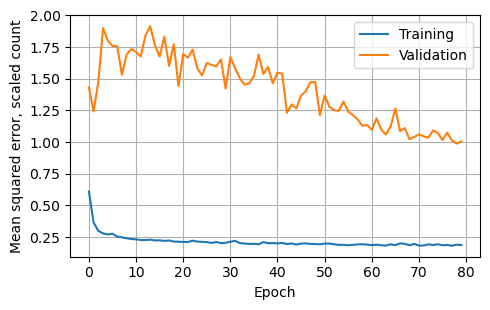

validation MAE 383.5
test MAE 275.2
test RMSE 404.6
test R2 0.615
test MAPE 55.2


In [10]:
torch.manual_seed(0)
generator = torch.Generator()
generator.manual_seed(0)
loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True, generator=generator)
model = Simple_Network(X_train.shape[1], 32, 1).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
train_loss, val_loss = [], []
for epoch in range(80):
    model.train()
    total = 0.0
    for Xb, yb in loader:
        loss = loss_fn(model(Xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    train_loss.append(total / len(loader.dataset))
    model.eval()
    with torch.no_grad():
        val_loss.append(loss_fn(model(X_valid), y_valid).item())

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(train_loss, label="Training")
ax.plot(val_loss, label="Validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error, scaled count")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
    pred_valid = model(X_valid).cpu().numpy().reshape(-1) * y_std + y_mean
    pred_test = model(X_test).cpu().numpy().reshape(-1) * y_std + y_mean
print("validation MAE", f"{mean_absolute_error(y_valid_np, pred_valid):.1f}")
print("test MAE", f"{mean_absolute_error(y_test_np, pred_test):.1f}")
keep = y_test_np >= 5
mape = np.mean(np.abs(y_test_np[keep] - pred_test[keep]) / y_test_np[keep]) * 100
print("test RMSE", f"{np.sqrt(mean_squared_error(y_test_np, pred_test)):.1f}")
print("test R2", f"{r2_score(y_test_np, pred_test):.3f}")
print("test MAPE", f"{mape:.1f}")


## Predicted count against rented count

The horizontal axis is the predicted count. The vertical axis is the rented count. A point on the solid line was predicted exactly. The dashed lines are 20% below and 20% above the prediction, `0.8 × predicted` and `1.2 × predicted`. A point between the dashed lines is within 20% of the predicted count.


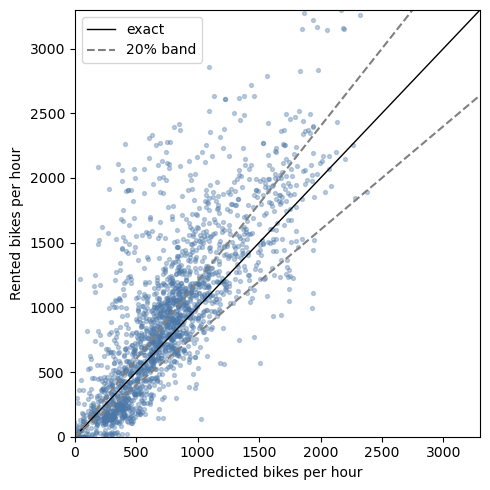

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pred_test, y_test_np, s=8, alpha=0.35, color="#4C78A8")
limit = max(float(y_test_np.max()), float(pred_test.max()))
grid = np.linspace(0, limit, 200)
ax.plot(grid, grid, color="black", linewidth=1, label="exact")
ax.plot(grid, 0.8 * grid, color="gray", linestyle="--", label="20% band")
ax.plot(grid, 1.2 * grid, color="gray", linestyle="--")
ax.set_xlabel("Predicted bikes per hour")
ax.set_ylabel("Rented bikes per hour")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.legend()
fig.tight_layout()
plt.show()


## Two weeks of the test set

The figure draws every hour from 1 September 2018 through 14 September 2018. Those fourteen days are inside the test set, which starts on 31 August, so the line has one point for every hour. One line is how many bikes were rented. The other is the prediction.


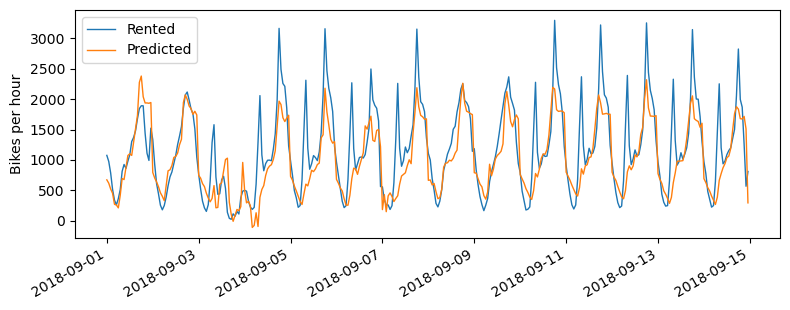

test hours in this window 336


In [12]:
drawn = test_hours.copy()
drawn["predicted"] = pred_test
drawn["time"] = pd.to_datetime(drawn["date"], dayfirst=True) + pd.to_timedelta(drawn["hour"], unit="h")
window = drawn[(drawn["time"] >= "2018-09-01") & (drawn["time"] < "2018-09-15")].sort_values("time")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(window["time"], window["rented"], label="Rented", linewidth=1)
ax.plot(window["time"], window["predicted"], label="Predicted", linewidth=1)
ax.set_ylabel("Bikes per hour")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print("test hours in this window", len(window))


On the test days, 31 August through 30 November, the 32-unit network has MAE about 275.2, RMSE about 404.6, R2 about 0.615, and MAPE about 55.2. The same fit has validation MAE about 383.5. The validation days are summer, when the average count is about 1030, against a training average of about 481, so those hours are the harder test of the fit. The September figure contains all 336 hours of the two weeks, in calendar order.
